In [29]:
import time
import pickle

In [30]:
def unPickle(filename):
    '''
    to shorten 3 lines into 1 line
    '''
    with open(filename,'rb') as f:
        output = pickle.load(f)
    f.close()
    return output

def makePickle(filename,data):
    with open(filename,'wb') as f:
        pickle.dump(data,f)
    f.close()

In [31]:
# import seabreeze (use 'pyseabreeze')
import seabreeze.spectrometers as sb

import os
import math
import numpy as np
import matplotlib.pyplot as plt
import time
import datetime

# set graphics to be plotted in the notebook
%matplotlib inline 

devices = sb.list_devices()
print (devices)

[<SeaBreezeDevice USB2000PLUS:USB2+F02461>]


In [32]:
# close the connection if opened
if spec:
    print('spec is there')
    spec.close()

spec is there


In [33]:
spec = sb.Spectrometer.from_first_available()
# spec = sb.Spectrometer.from_serial_number("S03615")#STS-UV-L-100-400-SMA
# serial number
print (spec.serial_number)
# model
print (spec.model)
# number of pixels (as returned by seabreeze)
print (spec.pixels)
# set the integration time in microseconds
spec.integration_time_micros(400000)
time.sleep(2)

USB2+F02461
USB2000PLUS
2048


In [69]:
# move_to_esp32(60,20)

ESP32 Response: Moved to PAN=60, TILT=20


In [20]:
np.min(nm),np.max(nm)

(np.float64(338.6034821), np.float64(1036.2438976222043))

In [26]:
#set integration time
micro_time=.2*1e6 # us
spec.integration_time_micros(micro_time)
# load dark noise
#dark_ = np.load(f'../../telescope/data/darkNoise/darkNoise_{micro_time/1e3}ms.npy')

In [58]:
spec.integration_time_micros(1000) # 1ms is the lowest integration time

In [59]:
darks = []
for ii in range(10):
    _,dark_ = spec.spectrum()
    darks.append(dark_)
    time.sleep(2)
darks = np.asarray(darks)

In [60]:
darks.shape

(10, 2048)

In [61]:
dark_1ms = np.mean(darks,axis=0)

In [64]:
np.max(dark_1ms)

np.float64(25635.48413793103)

In [38]:
# dark_200ms = np.mean(darks,axis=0)

(2048,)

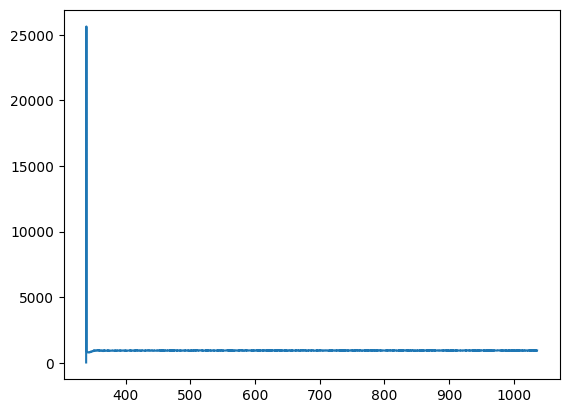

In [62]:
plt.plot(nm,dark_1ms)

In [89]:
capped_nm_idx = np.where((nm < 700) & (nm > 339))
capped_nm = nm[capped_nm_idx]

In [94]:
target_nm_range=5
target_nm1=360
capped_target_nm1_idx = np.where((nm < target_nm1+target_nm_range) & (nm > target_nm1-target_nm_range))
target_nm2=511
capped_target_nm2_idx = np.where((nm < target_nm2+target_nm_range) & (nm > target_nm2-target_nm_range))

51.3850026525199 50.410894636015335


/var/folders/l4/pwnj9skj16x_35bhhr9305900000gn/T/ipykernel_61046/2166890723.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


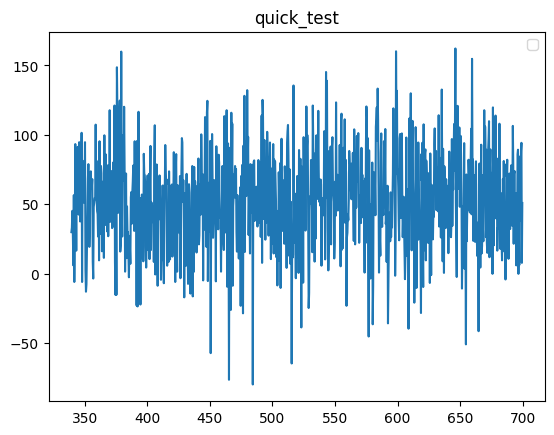

In [117]:
#set integration time
micro_time=1e3# us
spec.integration_time_micros(micro_time)
# move_to_esp32(0,-20) # .1 s is enough
nm,ints = spec.spectrum()
ints_clean = ints-dark_1ms
plt.plot(capped_nm,ints_clean[capped_nm_idx])
# plt.plot(nm,ints-dark_)
# plt.vlines(nm[np.argmax(ints)],np.min(ints),np.max(ints),color='r',label=nm[np.argmax(ints)])
print(np.mean(ints_clean[capped_target_nm1_idx]),np.mean(ints_clean[capped_target_nm2_idx]))
plt.title('quick_test'.format(micro_time/1e3))
# plt.ylim(np.min(ints),np.max(ints))
plt.legend()

/var/folders/l4/pwnj9skj16x_35bhhr9305900000gn/T/ipykernel_61046/2938453318.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


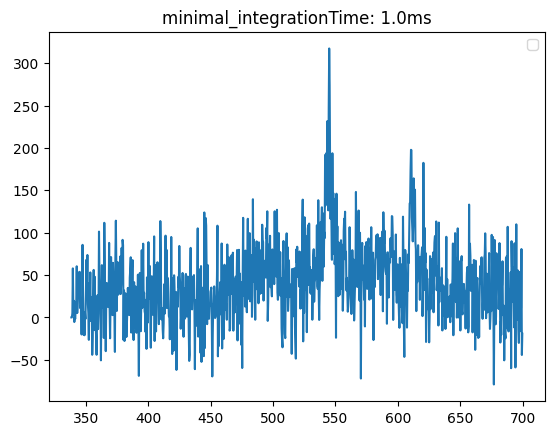

In [82]:
plt.plot(capped_nm,(ints-dark_1ms)[capped_nm_idx])
# plt.plot(nm,ints-dark_)
# plt.vlines(nm[np.argmax(ints)],np.min(ints),np.max(ints),color='r',label=nm[np.argmax(ints)])
plt.title(f'minimal_integrationTime: {micro_time/1e3}ms')
# plt.ylim(np.min(ints),np.max(ints))
plt.legend()

## how to determine integration time

In [82]:
h_left = 60
h_right = -20
stepsize_h = 2

h_steps = (np.abs(h_left)+np.abs(h_right))//stepsize_h

v_top = 30
v_threshold = -20
v_down = -20
stepsize_top=2
stepsize_down=2
v_steps = np.abs(v_top-v_threshold)//stepsize_top+np.abs(v_threshold-v_down)//stepsize_down

sleep_time=.4

In [89]:
# Create dictionary
params_dict = {
    "h_left": h_left,
    "h_right": h_right,
    "stepsize_h": stepsize_h,
    "h_steps": int(h_steps),  # Convert to int for clean output

    "v_top": v_top,
    "v_threshold": v_threshold,
    "v_down": v_down,
    "stepsize_top": stepsize_top,
    "stepsize_down": stepsize_down,
    "v_steps": int(v_steps),  # Convert to int for clean output

    "micro_time": micro_time,
    "micro_time_down": None,
    "sleep_time":sleep_time,
    "top_dark_":None,
    "down_dark_":None,
    'weather':'before sunrise',
    'cmt':'morning testing,rain,balcony, no visible sun'
}

## test

In [ ]:
import numpy as np
from collections import deque

In [148]:
class IntTimeScheduler:
    def __init__(
        self,
        target_counts=1_000,
        accept_max=65_535,
        min_int_ms=1,
        max_int_ms=2000.0,
        alpha0=0.8,                  # aggressive early, then decays
        min_factor=1/3,              # clamp multiplicative jumps
        max_factor=3.0,
        ema_beta=0.6,                # smooth measured brightness
        percentile=99.9,
        cooldown_iters=1             # skip updates right after hard backoff
    ):
        self.target = float(target_counts)
        self.accept_max = float(accept_max)
        self.min_int = float(min_int_ms)
        self.max_int = float(max_int_ms)
        self.alpha0 = float(alpha0)
        self.min_factor = float(min_factor)
        self.max_factor = float(max_factor)
        self.beta = float(ema_beta)
        self.perc = float(percentile)
        self.cooldown_iters = int(cooldown_iters)
        self.t = 1
        self.ema_measure = None
        self.direction_hist = deque(maxlen=6)
        self.cooldown = 0

    def _alpha(self):
        # classic decay: α(t) = α0 / √t; stable, simple
        return self.alpha0 / np.sqrt(self.t)

    def _robust_measure(self, raw):
        # avoid single-pixel spikes; use high percentile
        return float(np.percentile(raw, self.perc))

    def _update_ema(self, m):
        if self.ema_measure is None:
            self.ema_measure = m
        else:
            self.ema_measure = self.beta * m + (1 - self.beta) * self.ema_measure
        return self.ema_measure

    def propose(self, current_int_ms, raw_counts):
        # 1) saturation guard using true max
        max_val = float(np.max(raw_counts))
        if max_val >= 0.995 * self.accept_max:
            # hard backoff and short cooldown to let sensor settle
            next_int = max(current_int_ms * 0.25, self.min_int)
            self.cooldown = self.cooldown_iters
            self.direction_hist.append(-1)
            self.t += 1
            return next_int, {"reason": "saturation_backoff", "max": max_val}

        # 2) compute robust brightness and smooth it
        meas = self._robust_measure(raw_counts)
        meas = self._update_ema(meas)

        # 3) compute multiplicative factor with annealed exponent
        ratio = self.target / max(meas, 1.0)
        alpha = self._alpha()

        # if recently oscillating, damp α further
        if len(self.direction_hist) == self.direction_hist.maxlen and sum(self.direction_hist) == 0:
            alpha *= 0.5

        factor = ratio ** alpha
        factor = float(np.clip(factor, self.min_factor, self.max_factor))

        # 4) optional cooldown: freeze increases right after backoff
        if self.cooldown > 0 and factor > 1.0:
            factor = 1.0
            self.cooldown -= 1

        next_int = np.round(float(np.clip(current_int_ms * factor, self.min_int, self.max_int)),3)

        # 5) record direction for oscillation detection
        self.direction_hist.append(1 if factor > 1.0 else (-1 if factor < 1.0 else 0))

        self.t += 1
        return next_int, {
            "reason": "ratio_update",
            "measure": meas,
            "ratio": ratio,
            "alpha": alpha,
            "factor": factor
        }


In [149]:
class IntTimeScheduler:
    def __init__(self,
        target_counts=100, # num photo for a good exposure
        accept_max=65_535,
        min_int_ms=1,
        max_int_ms=2000.0,
        # ↑ direction
        alpha0=0.8,
        min_factor=1/3, max_factor=3.0,
        # ↓ direction (new)
        alpha0_dec=0.8,                 # stronger than ↑
        min_factor_dec=0.05,            # allow big cuts
        # common
        ema_beta=0.6, percentile=99.9,
        cooldown_iters=1,
        deadband_rel=0.02               # ±2% no-op band
    ):
        self.target = float(target_counts)
        self.accept_max = float(accept_max)
        self.min_int = float(min_int_ms)
        self.max_int = float(max_int_ms)
        self.alpha0 = float(alpha0)
        self.alpha0_dec = float(alpha0_dec)
        self.min_factor = float(min_factor)
        self.max_factor = float(max_factor)
        self.min_factor_dec = float(min_factor_dec)
        self.beta = float(ema_beta)
        self.perc = float(percentile)
        self.cooldown_iters = int(cooldown_iters)
        self.deadband_rel = float(deadband_rel)
        self.t = 1
        self.ema_measure = None
        self.prev = None  # (int_ms, meas)
        self.direction_hist = deque(maxlen=6)
        self.cooldown = 0

    def _alpha_inc(self):  # ↑ anneal
        return self.alpha0 / np.sqrt(self.t)

    def _alpha_dec(self):  # ↓ anneal, separate track
        return self.alpha0_dec / np.sqrt(self.t)

    def _robust_measure(self, raw):
        return float(np.percentile(raw, self.perc))

    def _update_ema(self, m):
        self.ema_measure = m if self.ema_measure is None else self.beta*m + (1-self.beta)*self.ema_measure
        return self.ema_measure

    def _headroom_backoff(self, headroom):
        # Stronger cuts as we approach saturation
        if headroom < 200:   return 0.10
        if headroom < 1000:  return 0.25
        if headroom < 3000:  return 0.50
        return None  # no forced cut

    def _predictive_factor(self, current_int_ms, meas):
        # Estimate slope d(meas)/d(int_ms) using last point; fall back if unavailable or flat
        if not self.prev:
            return None
        prev_int_ms, prev_meas = self.prev
        dI = current_int_ms - prev_int_ms
        dM = meas - prev_meas
        if abs(dI) < 1e-12 or abs(dM) < 1e-6:
            return None
        slope = dM / dI
        # desired Δint to reach target (linearized)
        delta_int = (self.target - meas) / slope
        pred_int = np.clip(current_int_ms + delta_int, self.min_int, self.max_int)
        if pred_int <= 0:
            return None
        return float(pred_int / current_int_ms)

    def propose(self, current_int_ms, raw_counts):
        # 0) saturation guard
        max_val = float(np.max(raw_counts))
        if max_val >= 0.995 * self.accept_max:
            next_int = max(current_int_ms * 0.25, self.min_int)
            self.cooldown = self.cooldown_iters
            self.direction_hist.append(-1)
            self.t += 1
            self.prev = (current_int_ms, self.ema_measure if self.ema_measure is not None else 0.0)
            return next_int, {"reason": "saturation_backoff", "max": max_val}

        # 1) robust measure + smoothing
        meas = self._update_ema(self._robust_measure(raw_counts))

        # 2) deadband
        rel_err = abs(meas / self.target - 1.0)
        if rel_err < self.deadband_rel:
            self.t += 1
            self.prev = (current_int_ms, meas)
            self.direction_hist.append(0)
            return current_int_ms, {"reason": "deadband_hold", "measure": meas}

        # 3) compute ratio factor and optional prediction
        ratio = self.target / max(meas, 1.0)
        if meas < self.target:
            alpha = self._alpha_inc()
            factor_r = float(np.clip(ratio**alpha, self.min_factor, self.max_factor))
            factor_p = self._predictive_factor(current_int_ms, meas)
            # blend prediction gently on ↑ to avoid overshoot
            if factor_p is not None and factor_p > 1.0:
                factor = 0.5*factor_r + 0.5*float(np.clip(factor_p, 1.0, self.max_factor))
            else:
                factor = factor_r
        else:
            # ↓ direction
            alpha = self._alpha_dec()
            # headroom-based override near saturation
            headroom = self.accept_max - max_val
            forced = self._headroom_backoff(headroom)
            if forced is not None:
                factor = forced
            else:
                # ratio-based decay
                # ratio < 1 → reduce; clamp to [min_factor_dec, 1]
                factor_r = float(np.clip(ratio**alpha, self.min_factor_dec, 1.0))
                factor_p = self._predictive_factor(current_int_ms, meas)
                # prefer prediction when reducing; it’s safer to cut deeper
                if factor_p is not None and factor_p < 1.0:
                    factor = float(np.clip(factor_p, self.min_factor_dec, 1.0))
                    # blend toward stronger of the two cuts
                    factor = min(factor, factor_r)
                else:
                    factor = factor_r

        # 4) cooldown behavior: block increases right after forced backoff
        if self.cooldown > 0 and factor > 1.0:
            factor = 1.0
            self.cooldown -= 1

        next_int = np.round(float(np.clip(current_int_ms * factor, self.min_int, self.max_int)),3)

        # 5) record, advance
        self.direction_hist.append(1 if factor > 1.0 else -1 if factor < 1.0 else 0)
        self.t += 1
        self.prev = (current_int_ms, meas)
        return next_int, {
            "reason": "ratio_dec" if meas > self.target else "ratio_inc",
            "measure": meas, "ratio": ratio, "alpha": alpha, "factor": factor
        }


In [150]:
sched = IntTimeScheduler(
    target_counts=1_000,
    accept_max=65_535,
    min_int_ms=1,
    max_int_ms=2000.0,
    alpha0=0.8,         # start assertive
    min_factor=1/3,
    max_factor=3.0,
    ema_beta=0.6,
    percentile=99.9
)

In [ ]:
current_int = 1  # ms
iter_counter = 0
while True:
    print(f'iter No. {iter_counter}') 
    print(f'current integration time: {current_int} ms')
    spec.integration_time_micros(current_int * 1e3)  # ms -> µs
    _, raw_value = spec.spectrum()
    if iter_counter ==0:
        iter_counter += 1
    else:
        ## OVEROVERexposed, just out
        if np.max(raw_value) >= 65_535 and current_int <= sched.min_int + 1e-9:
            break  # irrecoverable overexposure at min integration time
        
        ## let's see how much UV and G we have 
        ints_clean = raw_value - dark_1ms
        target_nm1_mean = float(np.mean(ints_clean[capped_target_nm1_idx]))
        target_nm2_mean = float(np.mean(ints_clean[capped_target_nm2_idx]))
        print(f'target_UV_range_mean: {target_nm1_mean},target_Green_range_mean: {target_nm2_mean}')
        
        if target_nm1_mean > 200 and target_nm2_mean > 300:
            print('good enough, exit')
            break
    
        next_int, info = sched.propose(current_int, raw_value)
        current_int = next_int
        iter_counter += 1

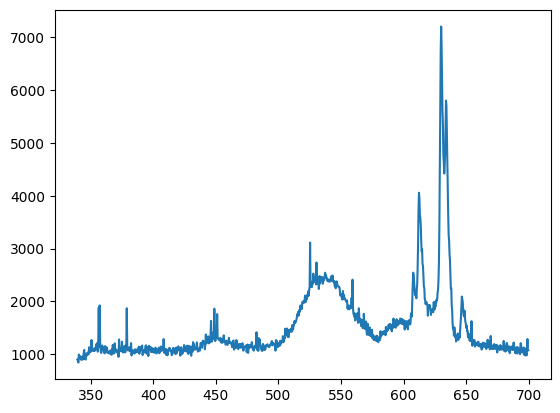

In [144]:
plt.plot(nm[capped_nm_idx],raw_value[capped_nm_idx])

In [99]:
def increase_int_t(spectrometer,current_t_ms,delta_ms=1):
    spectrometer.integration_time_micros((current_t_ms+delta_ms)*1e3)

In [ ]:
ACCEPT_MAX = 65535.0
current_int = 0.01*1e3 #ms
iter_counter = 0
while True:
    print(f'iter No. {iter_counter}') 
    print(f'current integration time: {current_int} ms')
    spec.integration_time_micros(current_int*1e3)
    
    _,raw_value = spec.spectrum()
    ints_clean = raw_value-dark_1ms
    target_nm1_mean = np.mean(ints_clean[capped_target_nm1_idx])
    target_nm2_mean = np.mean(ints_clean[capped_target_nm2_idx])

    ## overexposed
    if np.max(raw_value) > ACCEPT_MAX and current_int ==1:
        print('wait for a darker time or a better spectrometer')
        # time.sleep(98765432)
        break

    ## enough exposed
    if target_nm1 >1000 and target_nm2>1000:
        print('good enough, exit')
        break
    else:
        delta_ms = 1
        increase_int_t(spec,current_int,delta_ms)
        current_int = delta_ms+current_int
    iter_counter = iter_counter+1

In [ ]:
ACCEPT_MAX = 65535.0
current_int = 0.01*1e3 #ms
while True:
    spectrometer.integration_time_micros(current_int*1e3)
    print(f'current integration time: {current_int} ms')
    _,raw_value = spectrometer.spectrum()
    ints_clean = raw_value-dark_1ms
    target_nm1_mean = np.mean(ints_clean[capped_target_nm1_idx])
    target_nm2_mean = np.mean(ints_clean[capped_target_nm2_idx])

    ## overexposed
    if np.max(raw_value) > ACCEPT_MAX and current_int ==1:
        print('wait for a darker time or a better spectrometer')
        # time.sleep(98765432)
        break

    ## enough exposed
    if target_nm1 >1000 and target_nm2>1000:
        print('good enough, exit')
        break
    else:
        delta_ms = 1
        increase_int_t(spectrometer,current_int,delta_ms)
        current_int = delta_ms+current_int
    
    elif np.max(raw_value) > ACCEPT_MAX and current_int>=2:
        print('overexposed, REDUCE the integration time by 1ms')
        current_int = current_int-1
        spectrometer.integration_time_micros(current_int*1e3)
    else:
        if ACCEPT_SPEC_LOW <= np.mean(raw_value) <= ACCEPT_SPEC_HIGH:
            return current_int
        elif np.mean(raw_value) > ACCEPT_SPEC_HIGH:
            print("OVEREXPOSED, mean of raw :",np.mean(raw_value))
            median_index -= 1
        elif np.mean(raw_value) < ACCEPT_SPEC_LOW:
            print("UNDEREXPOSED, mean of raw :",np.mean(raw_value))
            median_index += 1
    print(f'median_indx {median_index}, current int time {sorted_times[median_index]}ms:')
    if median_index < 0 or median_index >= len(sorted_times):
        print("No suitable integration time found within the range.")
        print("MEASURE SOME MORE INTEGRATION TIMES")
        if median_index<0:
            return sorted_times[0]
        else:
            return sorted_times[-1]
    else:
        # Update the current integration time
        current_int = sorted_times[median_index]

In [ ]:
def get_optimal_integration_time(current_int, spectrometer,previous_ints=None):
    """
    Finds the optimal integration time to achieve a spectral reading between 8000 and 15000.

    Parameters:
        all_int_times (list): List of available integration times in milliseconds.
        spectrometer (object): Spectrometer device with a `set_integration_time` and `read` method.

    Returns:
        int: Optimal integration time in milliseconds.
    """
    
    # sorted_times = sorted(all_int_times)
    # if previous_ints is None:
    #     median_index = len(sorted_times) // 2
    #     print(f'{len(sorted_times)} integrationtime')
    #     current_int = sorted_times[median_index]
    #     print(f'current int time {current_int}ms:')
    # else:
    #     median_index = sorted_times.index(previous_ints) if previous_ints in sorted_times else len(sorted_times) // 2
    #     current_int = sorted_times[median_index]

    while True:
        spectrometer.integration_time_micros(current_int*1e3)
        _,raw_value = spectrometer.spectrum()
        
        
        print(np.max(raw_value))
        if np.max(raw_value) > ACCEPT_MAX:
            # check if the raw_value is too high
            # decrease the integration time
           median_index -= 1
        else:
            print(np.mean(ints_clean[capped_target_nm1_idx]),np.mean(ints_clean[capped_target_nm2_idx]))
            if ACCEPT_SPEC_LOW <= np.mean(raw_value) <= ACCEPT_SPEC_HIGH:
                return current_int
            elif np.mean(raw_value) > ACCEPT_SPEC_HIGH:
                print("OVEREXPOSED, mean of raw :",np.mean(raw_value))
                median_index -= 1
            elif np.mean(raw_value) < ACCEPT_SPEC_LOW:
                print("UNDEREXPOSED, mean of raw :",np.mean(raw_value))
                median_index += 1
        print(f'median_indx {median_index}, current int time {sorted_times[median_index]}ms:')
        if median_index < 0 or median_index >= len(sorted_times):
            print("No suitable integration time found within the range.")
            print("MEASURE SOME MORE INTEGRATION TIMES")
            if median_index<0:
                return sorted_times[0]
            else:
                return sorted_times[-1]
        else:
            # Update the current integration time
            current_int = sorted_times[median_index]

In [ ]:
micro_time_MAX= 2 * 1e6
micro_time = .02*1e6
spec.integration_time_micros(micro_time)
while micro_time<= micro_time_MAX:
    ## first part of ONE WHOLE SCAN: determine integration time
    move_to_esp32(h_left,v_top)
    nm,ints = spec.spectrum()
    if np.min(ints)/np.max(ints)>.2:
        micro_time_down = .5*1e6 #micro_time*10
        ## start scan the inital vertical to find the v_threshold
        ## assume v_threshold == -20
        ## start scanning
        output = np.zeros((v_steps+1,h_steps+1,1024))
        print(f'start :{datetime.datetime.now()}')
        start_t = str(datetime.datetime.now())[:19].replace('-','_').replace(':','_').replace(' ','_')
        params_dict['start_t'] = start_t

        print('start at: ',datetime.datetime.now())
        params_dict['scan_pattern']='ul_ll_ur_lr'
        for hh,pan_ in enumerate(range(h_left,h_right-stepsize_h,-stepsize_h)):
            for vv,tilt_ in enumerate(range(v_top,v_down-stepsize_top,-stepsize_top)):
                move_to_esp32(pan_,tilt_)
                if tilt_<v_threshold:
                    spec.integration_time_micros(micro_time_down)
                    
                time.sleep(sleep_time)
                _,output[vv,hh] = spec.spectrum()
        print('finished at: ',datetime.datetime.now())
        
        end_t = str(datetime.datetime.now())[:19].replace('-','_').replace(':','_').replace(' ','_')
        params_dict['raw_record'] = output
        params_dict['end_t'] = end_t
        makePickle(f'../data/sts_reconstruction/{end_t}.pkl',params_dict)
        break
    else:
        micro_time = micro_time+.1*1e6
        params_dict['micro_time']=micro_time
        spec.integration_time_micros(micro_time)
        print(f'new integration time {micro_time}')
print(f'integration time {micro_time/1e6} s')

In [85]:
for hh,pan_ in enumerate(range(h_left,h_right,-stepsize_h)):
    print(hh,pan_)

0 60
1 58
2 56
3 54
4 52
5 50
6 48
7 46
8 44
9 42
10 40
11 38
12 36
13 34
14 32
15 30
16 28
17 26
18 24
19 22
20 20
21 18
22 16
23 14
24 12
25 10
26 8
27 6
28 4
29 2
30 0
31 -2
32 -4
33 -6
34 -8
35 -10
36 -12
37 -14
38 -16
39 -18


In [50]:
params_dict['cmt'] = 'morning around sunrise time'
makePickle(f'./{end_t}.pkl',params_dict)

In [56]:
output.shape

(21, 31, 1024)

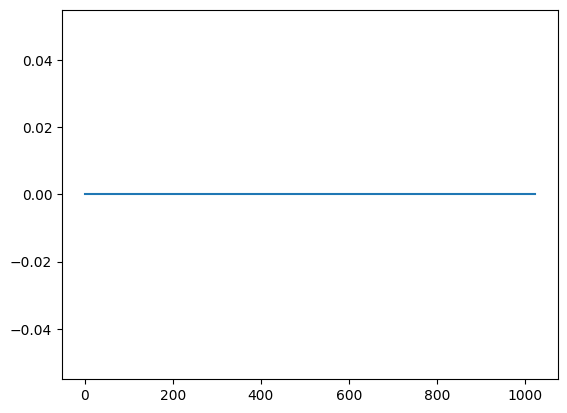

In [62]:
plt.plot(output[16,30])

In [49]:
import pickle

In [19]:
ints[g_loc]/np.max(ints)-ints[red_loc]/np.max(ints)<.1

np.True_

In [17]:
## save param_dict
import pickle
def unPickle(filename):
    '''
    to shorten 3 lines into 1 line
    '''
    with open(filename,'rb') as f:
        output = pickle.load(f)
    f.close()
    return output

def makePickle(filename,data):
    with open(filename,'wb') as f:
        pickle.dump(data,f)
    f.close()

## use different integration time at a certain elevation
### this can be automized (e.g. take a quick vertical line scan, find the drop-> vertical line)

In [18]:
## quick test in Feb2025

In [19]:
h_left = 30
h_right = -30
stepsize_h = 2

h_steps = (np.abs(h_left)+np.abs(h_right))//stepsize_h

v_top = 25
v_threshold = -20
v_down = -25
stepsize_top=2
stepsize_down=2
v_steps = np.abs(v_top-v_threshold)//stepsize_top+np.abs(v_threshold-v_down)//stepsize_down


micro_time_top = 1.0*1e6
micro_time_down = 1.0*1e6
top_dark_ = np.load(f'../../telescope/data/darkNoise/darkNoise_{micro_time_top/1e3}ms.npy')
down_dark_ = np.load(f'../../telescope/data/darkNoise/darkNoise_{micro_time_down/1e3}ms.npy')

In [21]:
# Create dictionary
params_dict = {
    "h_left": h_left,
    "h_right": h_right,
    "stepsize_h": stepsize_h,
    "h_steps": int(h_steps),  # Convert to int for clean output

    "v_top": v_top,
    "v_threshold": v_threshold,
    "v_down": v_down,
    "stepsize_top": stepsize_top,
    "stepsize_down": stepsize_down,
    "v_steps": int(v_steps),  # Convert to int for clean output

    "micro_time_top": micro_time_top,
    "micro_time_down": micro_time_down,
    "top_dark_":top_dark_,
    "down_dark_":down_dark_,
    'weather':'inside',
    'cmt':'testing cam-scanner sync'
}

In [22]:
output = np.zeros((v_steps+1,h_steps+1,1024))
print(output.shape)

(21, 31, 1024)


In [23]:
move_to_esp32(0,0)

ESP32 Response: Moved to PAN=0, TILT=0


In [24]:
import datetime
print(datetime.datetime.now())

2025-02-26 16:24:38.590492


In [25]:
start_t = str(datetime.datetime.now())[:19].replace('-','_').replace(':','_').replace(' ','_')
params_dict['start_t'] = start_t

In [ ]:
print('start at: ',datetime.datetime.now())
params_dict['scan_pattern']='ul_ll_ur_lr'
for hh,pan_ in enumerate(range(h_left,h_right,-stepsize_h)):
    for vv,tilt_ in enumerate(range(v_top,v_down,-stepsize_top)):
        move_to_esp32(pan_,tilt_)
        if tilt_>v_threshold:
            spec.integration_time_micros(micro_time_top)
        else:
            spec.integration_time_micros(micro_time_down)
        time.sleep(.5)
        _,output[vv,hh] = spec.spectrum()
print('finished at: ',datetime.datetime.now())

In [28]:
end_t = str(datetime.datetime.now())[:19].replace('-','_').replace(':','_').replace(' ','_')
params_dict['raw_record'] = output
params_dict['end_t'] = end_t
makePickle(f'{end_t}.pkl',params_dict)